# Лабораторна робота 3. Decision Tree та Random Forest
**Горбач Ангеліна, ФІ-31**

У цій роботі визначаю цінову категорію вживаного автомобіля за його характеристиками. Використовую набір [Vehicle Dataset from CarDekho](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho), файл `Car details v3.csv`.

Самостійно реалізую дерево рішень із критерієм Gini та пошуком оптимального поділу. Порівнюю його з деревом рішень і Random Forest із бібліотеки scikit-learn.

## 1. Аналіз та очищення даних

Спочатку перевіряю розмір набору, дублікати та пропуски. Видаляю повторні оголошення й записи з некоректними значеннями ціни, року або пробігу. Будую графіки розподілу ціни.

Початковий розмір: (8128, 13)
Дублікати: 1202
Пропуски:
 name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
Одиниці mileage:
 0
kmpl     7819
km/kg      88
Некоректні записи: 2
Після очищення: (6924, 13)


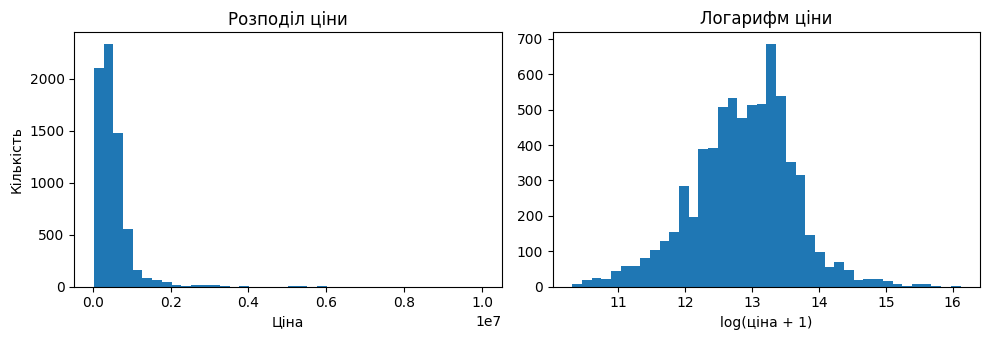

In [ ]:
import re
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

file_path = Path("Car details v3.csv")
if not file_path.exists():
    raise FileNotFoundError("Не знайдено файл Car details v3.csv.")

# Read the dataset and check data quality.
data = pd.read_csv(file_path)
print("Початковий розмір:", data.shape)
print("Дублікати:", data.duplicated().sum())
print("Пропуски:\n", data.isna().sum().to_string())
print("Одиниці mileage:\n", data["mileage"].str.extract(r"([A-Za-z/]+)$")[0].value_counts().to_string())
data = data.drop_duplicates().copy()

# Remove invalid values using fixed domain limits.
invalid_rows = ((data["selling_price"] <= 0) | (data["km_driven"] < 0)
                | (data["km_driven"] > 1_000_000) | (data["year"] < 1900)
                | (data["year"] > 2026)
                | data[["selling_price", "km_driven", "year"]].isna().any(axis=1))
print("Некоректні записи:", invalid_rows.sum())
data = data.loc[~invalid_rows].copy()
print("Після очищення:", data.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(data["selling_price"], bins=40)
axes[0].set(title="Розподіл ціни", xlabel="Ціна", ylabel="Кількість")
axes[1].hist(np.log1p(data["selling_price"]), bins=40)
axes[1].set(title="Логарифм ціни", xlabel="log(ціна + 1)")
plt.tight_layout()
plt.show()

Після видалення 1202 дублікатів і двох аномальних записів залишилося 6924 автомобілі. Пропуски технічних характеристик обробляю на етапі підготовки ознак. Високу ціну саму по собі не вважаю помилкою, тому дорогі автомобілі залишаю.

## 2. Ознаки, класи та поділ 50:50

Із текстових характеристик виділяю числові значення, а з назви автомобіля — марку. Крутний момент у kgm переводжу в Nm. Ціну перетворюю на три класи за межами з попередньої роботи: 300000 і 550000. Ділю дані порівну зі збереженням пропорцій класів.
Показники економічності у kmpl (км на літр) та km/kg (км на кілограм) зберігаю як окремі ознаки. Різні одиниці не об’єдную в одну числову шкалу.


Межі: [300000, 550000]
Навчання: 3462 Тест: 3462
         Навчання  Тест
низька       1124  1124
середня      1131  1132
висока       1207  1206
Частки класів:
          Навчання    Тест
низька     0.3247  0.3247
середня    0.3267  0.3270
висока     0.3486  0.3484


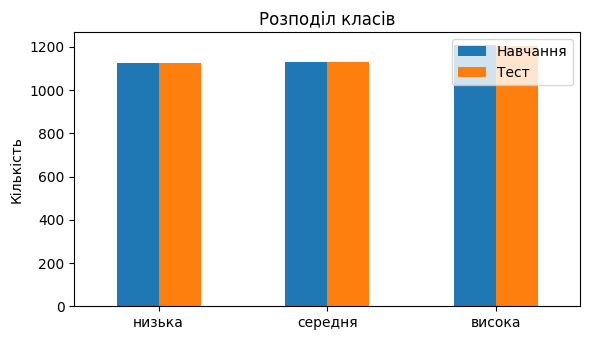

In [2]:
def first_number(value):
    if pd.isna(value):
        return np.nan
    # Extract the first numeric value from a text field.
    match = re.search(r"\d+(?:\.\d+)?", str(value))
    return float(match.group()) if match else np.nan


def torque_in_nm(value):
    number = first_number(value)
    return number * 9.80665 if "kgm" in str(value).lower() else number


def get_features(rows):
    # Use vehicle characteristics without the target price.
    features = rows[["year", "km_driven", "fuel", "seller_type", "transmission", "owner", "seats"]].copy()
    features["brand"] = rows["name"].str.split().str[0]
    # Keep distance per litre and distance per kilogram in separate features.
    mileage_text = rows["mileage"].astype("string").str.lower().str.strip()
    mileage_number = rows["mileage"].map(first_number)
    features["mileage_kmpl"] = mileage_number.where(mileage_text.str.endswith("kmpl", na=False))
    features["mileage_kmkg"] = mileage_number.where(mileage_text.str.endswith("km/kg", na=False))
    features["engine_cc"] = rows["engine"].map(first_number)
    features["max_power_bhp"] = rows["max_power"].map(first_number)
    features["torque_nm"] = rows["torque"].map(torque_in_nm)
    for column in ["mileage_kmpl", "mileage_kmkg", "engine_cc", "max_power_bhp", "torque_nm", "seats"]:
        features.loc[features[column] <= 0, column] = np.nan
    return features


# Fixed boundaries from the previous laboratory; no new quantiles are fitted.
price_limits = [300000, 550000]
class_names = ["низька", "середня", "висока"]
X_raw = get_features(data)
y = np.searchsorted(price_limits, data["selling_price"].to_numpy(), side="right")
# Preserve class proportions in the 50:50 split.
train_indices, test_indices = train_test_split(
    np.arange(len(data)), test_size=0.5, random_state=42, stratify=y)
X_train_raw = X_raw.iloc[train_indices]
X_test_raw = X_raw.iloc[test_indices]
y_train, y_test = y[train_indices], y[test_indices]

counts = pd.DataFrame({"Навчання": np.bincount(y_train, minlength=3),
                       "Тест": np.bincount(y_test, minlength=3)}, index=class_names)
print("Межі:", price_limits)
print("Навчання:", len(y_train), "Тест:", len(y_test))
print(counts.to_string())
print("Частки класів:\n", counts.div(counts.sum()).round(4).to_string())
counts.plot.bar(rot=0, figsize=(6, 3.5), ylabel="Кількість", title="Розподіл класів")
plt.tight_layout()
plt.show()

Отримала по 3462 записи для навчання та тестування. Низька категорія відповідає ціні до 300000, середня — від 300000 включно до 550000 невключно, висока — від 550000. За допомогою `stratify` зберігаю практично однакові частки класів; різниця в один запис виникає через непарну кількість автомобілів окремого класу. Ціну не включаю до вхідних ознак.

## 3. Кореляційний аналіз та залежності

На навчальній вибірці обчислюю кореляції Spearman між числовими ознаками, ціною та впорядкованим класом. Шукаю взаємопов’язані ознаки з абсолютною кореляцією не меншою за 0,7. Окремо порівнюю рік, пробіг, тип пального та коробку передач для різних цінових категорій.

Кореляції з ціною та класом (Spearman):
               selling_price  price_class
year                   0.707        0.670
km_driven             -0.298       -0.286
seats                  0.327        0.292
mileage_kmpl           0.020        0.044
mileage_kmkg           0.375        0.312
engine_cc              0.476        0.414
max_power_bhp          0.632        0.564
torque_nm              0.598        0.531


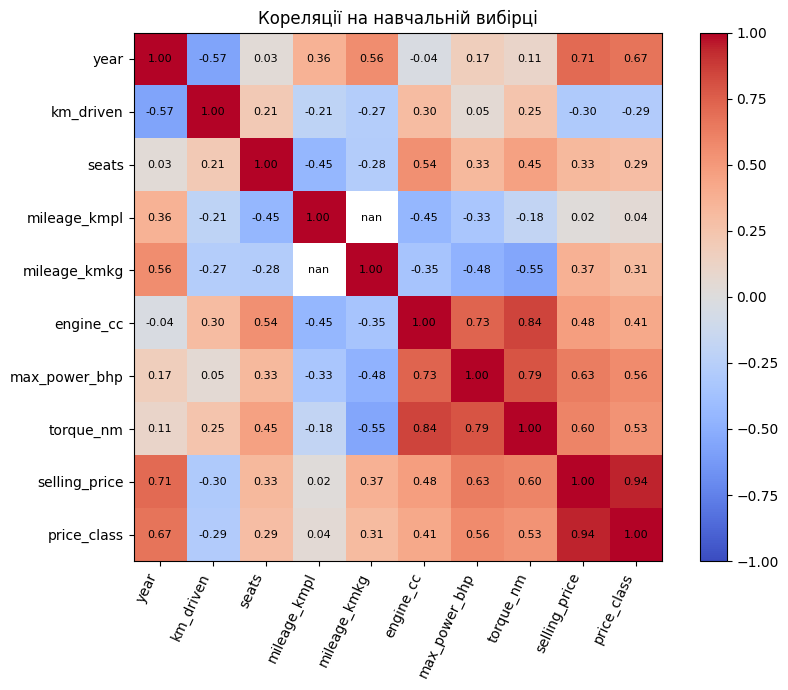

Сильно пов'язані ознаки (|r| ≥ 0.7): [('engine_cc', 'max_power_bhp', np.float64(0.728)), ('engine_cc', 'torque_nm', np.float64(0.845)), ('max_power_bhp', 'torque_nm', np.float64(0.792))]


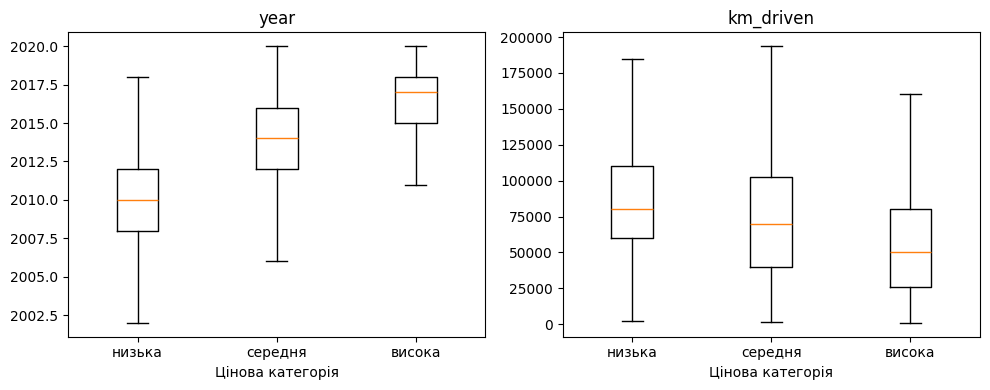


Частки класів за fuel
        низька  середня  висока
fuel                           
CNG      0.379    0.621   0.000
Diesel   0.210    0.319   0.471
LPG      0.850    0.150   0.000
Petrol   0.460    0.333   0.207

Частки класів за transmission
              низька  середня  висока
transmission                         
Automatic      0.062    0.179   0.759
Manual         0.349    0.340   0.311


In [ ]:
numeric_columns = ["year", "km_driven", "seats", "mileage_kmpl", "mileage_kmkg", "engine_cc", "max_power_bhp", "torque_nm"]
category_columns = ["brand", "fuel", "seller_type", "transmission", "owner"]

analysis = X_train_raw[numeric_columns].copy()
analysis["selling_price"] = data.iloc[train_indices]["selling_price"].to_numpy()
analysis["price_class"] = y_train

# Measure monotonic relationships using training rows only.
correlations = analysis.corr(method="spearman")
print("Кореляції з ціною та класом (Spearman):")
print(correlations.loc[numeric_columns, ["selling_price", "price_class"]].round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlations)), correlations.columns, rotation=65, ha="right")
ax.set_yticks(range(len(correlations)), correlations.columns)
for i in range(len(correlations)):
    for j in range(len(correlations)):
        ax.text(j, i, f"{correlations.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title("Кореляції на навчальній вибірці")
plt.tight_layout()
plt.show()

pairs = []
for i, first in enumerate(numeric_columns):
    for second in numeric_columns[i + 1:]:
        value = correlations.loc[first, second]
        if abs(value) >= 0.7:
            pairs.append((first, second, round(value, 3)))
print("Сильно пов'язані ознаки (|r| ≥ 0.7):", pairs or "не виявлено")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, column in zip(axes, ["year", "km_driven"]):
    ax.boxplot([X_train_raw.loc[y_train == k, column].dropna() for k in range(3)],
               tick_labels=class_names, showfliers=False)
    ax.set(title=column, xlabel="Цінова категорія")
plt.tight_layout()
plt.show()

# For nominal categories, compare class proportions instead of numeric correlations.
for column in ["fuel", "transmission"]:
    table = pd.crosstab(X_train_raw[column], y_train, normalize="index")
    table = table.reindex(columns=[0, 1, 2], fill_value=0)
    table.columns = class_names
    print("\nЧастки класів за", column)
    print(table.round(3).to_string())

Кореляція року випуску з ціною становить 0.707. Потужність і крутний момент мають додатний зв’язок, а пробіг — від’ємний. Виявила сильні зв’язки між об’ємом двигуна, потужністю та крутним моментом. Ці ознаки залишаю, оскільки дерева можуть використовувати їх для різних поділів.

Кореляції економічності обчислюються окремо для kmpl і km/kg за доступними парами значень. Для km/kg записів значно менше, тому цей результат менш надійний. Кореляції описують залежність і не доводять причинність.


NaN між mileage_kmpl і mileage_kmkg означає, що кореляцію неможливо обчислити: ці ознаки не мають спільних заповнених рядків, оскільки використовують різні одиниці. Це очікуваний результат.


## 4. Підготовка даних

Числові пропуски заповнюю медіанами, категоріальні — найчастішими значеннями. Категорії перетворюю за допомогою One-Hot кодування. Для добору параметрів відокремлюю 20% навчальної вибірки на валідацію. Підготовку навчаю лише на внутрішній навчальній частині.
Для автомобіля заповнена лише ознака економічності з відповідною одиницею; інша має структурний пропуск. Медіани обчислюю окремо для кожної ознаки лише на навчальних даних. Тип пального також зберігаю серед входів.


In [ ]:
def make_preprocessor():
    numbers = SimpleImputer(strategy="median")
    categories = Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", numbers, numeric_columns),
                              ("cat", categories, category_columns)])


print("Пропуски в навчальних ознаках:\n", X_train_raw.isna().sum().to_string())

# Keep validation separate when fitting preprocessing.
fit_indices, val_indices = train_test_split(
    np.arange(len(y_train)), test_size=0.2, random_state=42, stratify=y_train)
pre_val = make_preprocessor()
X_fit = pre_val.fit_transform(X_train_raw.iloc[fit_indices])
X_val = pre_val.transform(X_train_raw.iloc[val_indices])
y_fit, y_val = y_train[fit_indices], y_train[val_indices]
print("Внутрішнє навчання:", X_fit.shape, "Валідація:", X_val.shape)

Пропуски в навчальних ознаках:
 year                0
km_driven           0
fuel                0
seller_type         0
transmission        0
owner               0
seats              97
brand               0
mileage_kmpl      152
mileage_kmkg     3417
engine_cc          97
max_power_bhp      98
torque_nm          98
Внутрішнє навчання: (2769, 52) Валідація: (693, 52)


Для внутрішнього навчання отримала 2769 записів, для валідації — 693. Після кодування маю 52 ознаки. Масштабування не застосовую: дерева порівнюють значення ознак із порогами. Тестову вибірку під час добору параметрів не використовую.

## 5. Власне дерево рішень

Реалізую обчислення Gini, пошук найкращого поділу та рекурсивну побудову дерева. Для кожної ознаки перевіряю пороги між різними сусідніми значеннями й обираю поділ із найменшою зваженою нечистотою. У листі повертаю найчастіший клас.

In [ ]:
def gini(labels):
    counts = np.bincount(labels)

    # Gini is zero when all samples belong to one class.
    probabilities = counts / len(labels)
    return 1 - np.sum(probabilities ** 2)


class OwnDecisionTree:
    def __init__(self, max_depth=6, min_samples_leaf=5):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y):
        self.n_classes = int(np.max(y)) + 1
        self.root = self.build_tree(np.asarray(X), np.asarray(y), depth=0)
        return self

    def best_split(self, X, y):
        n = len(y)
        best_score = gini(y)
        best_feature, best_threshold = None, None
        total_counts = np.bincount(y, minlength=self.n_classes)
        for feature in range(X.shape[1]):
            order = np.argsort(X[:, feature], kind="stable")
            values, labels = X[order, feature], y[order]

            # Evaluate all boundaries between distinct adjacent feature values.
            positions = np.arange(1, n)
            valid = ((values[:-1] < values[1:])
                     & (positions >= self.min_samples_leaf)
                     & (n - positions >= self.min_samples_leaf))
            positions = positions[valid]
            if len(positions) == 0:
                continue
            class_matrix = np.eye(self.n_classes, dtype=int)[labels]

            # Count classes on each side of every candidate split.
            left_counts = np.cumsum(class_matrix, axis=0)[positions - 1]
            right_counts = total_counts - left_counts
            left_gini = 1 - np.sum((left_counts / positions[:, None]) ** 2, axis=1)
            right_gini = 1 - np.sum((right_counts / (n - positions)[:, None]) ** 2, axis=1)

            # Weight child impurities by their sample counts.
            scores = (positions * left_gini + (n - positions) * right_gini) / n
            index = np.argmin(scores)
            if scores[index] < best_score - 1e-12:
                best_score = scores[index]
                best_feature = feature
                pos = positions[index]
                best_threshold = values[pos - 1] + (values[pos] - values[pos - 1]) / 2
        return best_feature, best_threshold

    def build_tree(self, X, y, depth):
        prediction = int(np.bincount(y, minlength=self.n_classes).argmax())
        node = {"prediction": prediction, "samples": len(y), "gini": gini(y)}

        # Stop at pure nodes or when size and depth limits are reached.
        if (depth >= self.max_depth or len(y) < 2 * self.min_samples_leaf
                or node["gini"] <= 1e-12):
            return node
        feature, threshold = self.best_split(X, y)
        if feature is None:
            return node
        left = X[:, feature] <= threshold
        node["feature"] = feature
        node["threshold"] = threshold

        # Recursively build the two child nodes.
        node["left"] = self.build_tree(X[left], y[left], depth + 1)
        node["right"] = self.build_tree(X[~left], y[~left], depth + 1)
        return node

    def predict_one(self, row):
        node = self.root
        
        # Follow split rules until a leaf is reached.
        while "feature" in node:
            node = node["left"] if row[node["feature"]] <= node["threshold"] else node["right"]
        return node["prediction"]

    def predict(self, X):
        return np.array([self.predict_one(row) for row in np.asarray(X)])

Зупиняю поділ, якщо досягнута максимальна глибина, у вузлі залишився один клас або записів недостатньо для двох листів. Також завершую побудову вузла, якщо жодний поділ не зменшує Gini. Глибину та мінімальний розмір листа використовую для обмеження перенавчання.

## 6. Добір параметрів на валідації

Для власного дерева перевіряю глибини 4, 6, 8 і 10 та мінімальні розміри листа 5 і 15. Для лісу перевіряю глибини 10, 16 та без обмеження, розміри листа — 1 і 5. Обираю параметри за macro F1, щоб однаково враховувати всі класи.

У лісі використовую 200 дерев як компроміс між часом і стабільністю результату. `sqrt` задає випадковий вибір частини ознак у кожному вузлі; кожне дерево навчається на bootstrap-вибірці.

In [ ]:
tree_scores = []
for depth in [4, 6, 8, 10]:
    for leaf_size in [5, 15]:
        model = OwnDecisionTree(max_depth=depth, min_samples_leaf=leaf_size).fit(X_fit, y_fit)
        score = f1_score(y_val, model.predict(X_val), average="macro")
        tree_scores.append({"max_depth": depth, "min_samples_leaf": leaf_size, "Validation F1": score})
tree_results = pd.DataFrame(tree_scores)
print(tree_results.round(4).to_string(index=False))

# Select parameters on validation, without using test data.
best_tree = max(tree_scores, key=lambda row: row["Validation F1"])
tree_params = {key: best_tree[key] for key in ["max_depth", "min_samples_leaf"]}

forest_scores = []
for depth in [None, 10, 16]:
    for leaf_size in [1, 5]:
        model = RandomForestClassifier(n_estimators=200, max_depth=depth,
                    min_samples_leaf=leaf_size, max_features="sqrt", random_state=42, n_jobs=-1)
        model.fit(X_fit, y_fit)
        score = f1_score(y_val, model.predict(X_val), average="macro")
        forest_scores.append({"max_depth": depth, "min_samples_leaf": leaf_size, "Validation F1": score})
print(pd.DataFrame(forest_scores).round(4).to_string(index=False))
best_forest = max(forest_scores, key=lambda row: row["Validation F1"])
forest_params = {key: best_forest[key] for key in ["max_depth", "min_samples_leaf"]}
print("Параметри дерева:", tree_params)
print("Параметри лісу:", forest_params)

 max_depth  min_samples_leaf  Validation F1
         4                 5         0.7724
         4                15         0.7690
         6                 5         0.8107
         6                15         0.8020
         8                 5         0.8188
         8                15         0.8181
        10                 5         0.8141
        10                15         0.8192
 max_depth  min_samples_leaf  Validation F1
       NaN                 1         0.8320
       NaN                 5         0.8367
      10.0                 1         0.8526
      10.0                 5         0.8398
      16.0                 1         0.8392
      16.0                 5         0.8400
Параметри дерева: {'max_depth': 10, 'min_samples_leaf': 15}
Параметри лісу: {'max_depth': 10, 'min_samples_leaf': 1}


Для власного дерева обрала глибину 10 і мінімум 15 записів у листі: валідаційний macro F1 становить 0.8192. Для Random Forest обрала глибину 10 і мінімум 1 записів у листі: macro F1 становить 0.8526. Дереву sklearn задаю ті самі параметри, що й власному дереву, для порівняння реалізацій.

## 7. Остаточне навчання та помилки

Після добору параметрів заново навчаю підготовку ознак і всі три моделі на повній навчальній вибірці. Обчислюю точність і помилку на навчанні та тесті, тестовий macro F1 і час навчання. Будую матриці помилок.

Кількість ознак: 52
        Модель  Train accuracy  Test accuracy  Train error  Test error  Test macro F1  Час, с
 Власне дерево          0.8458         0.7969       0.1542      0.2031         0.7933  0.4778
Дерево sklearn          0.8458         0.7978       0.1542      0.2022         0.7942  0.0250
 Random Forest          0.9079         0.8310       0.0921      0.1690         0.8300  0.8212

 Власне дерево
              precision    recall  f1-score   support

      низька       0.83      0.84      0.84      1124
     середня       0.72      0.66      0.69      1132
      висока       0.83      0.89      0.86      1206

    accuracy                           0.80      3462
   macro avg       0.79      0.80      0.79      3462
weighted avg       0.79      0.80      0.79      3462


 Дерево sklearn
              precision    recall  f1-score   support

      низька       0.83      0.84      0.84      1124
     середня       0.72      0.66      0.69      1132
      висока       0.83    

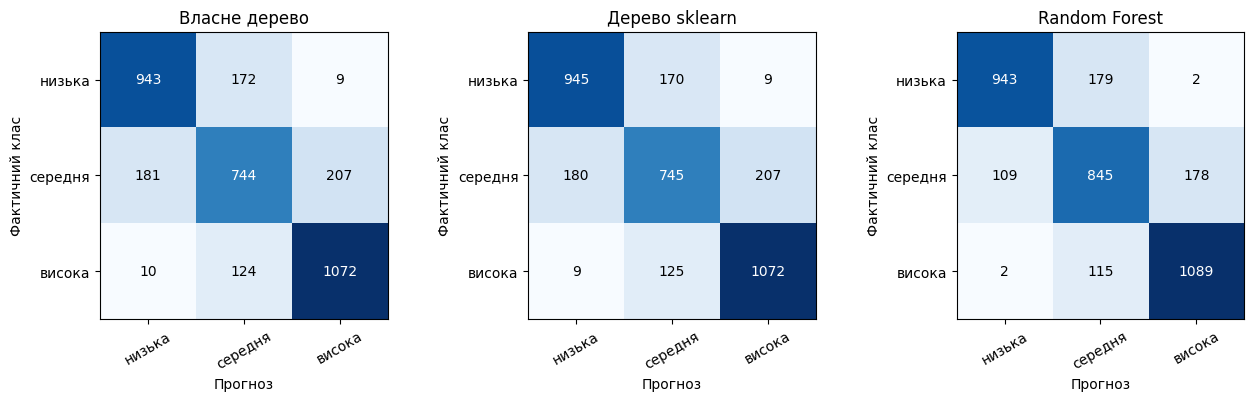

In [ ]:
# Refit preprocessing on all training rows.
pre_final = make_preprocessor()
X_train = pre_final.fit_transform(X_train_raw)
X_test = pre_final.transform(X_test_raw)
feature_names = pre_final.get_feature_names_out()
print("Кількість ознак:", X_train.shape[1])

models = {
    "Власне дерево": OwnDecisionTree(**tree_params),
    "Дерево sklearn": DecisionTreeClassifier(**tree_params, criterion="gini", random_state=42),
    "Random Forest": RandomForestClassifier(**forest_params, n_estimators=200,
                          max_features="sqrt", random_state=42, n_jobs=-1)}
results = []
for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    
    # Evaluate training and test errors separately.
    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)
    train_accuracy = accuracy_score(y_train, train_prediction)
    test_accuracy = accuracy_score(y_test, test_prediction)
    results.append({"Модель": name, "Train accuracy": train_accuracy,
                    "Test accuracy": test_accuracy, "Train error": 1 - train_accuracy,
                    "Test error": 1 - test_accuracy,
                    "Test macro F1": f1_score(y_test, test_prediction, average="macro"),
                    "Час, с": elapsed})
print(pd.DataFrame(results).round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, model) in zip(axes, models.items()):
    prediction = model.predict(X_test)
    matrix = confusion_matrix(y_test, prediction, labels=[0, 1, 2])
    ax.imshow(matrix, cmap="Blues")
    for row in range(3):
        for col in range(3):
            ax.text(col, row, matrix[row, col], ha="center", va="center",
                    color="white" if matrix[row, col] > matrix.max() / 2 else "black")
    ax.set_xticks(range(3), class_names, rotation=30)
    ax.set_yticks(range(3), class_names)
    ax.set(title=name, xlabel="Прогноз", ylabel="Фактичний клас")
    print("\n", name)
    print(classification_report(y_test, prediction, target_names=class_names, zero_division=0))
plt.tight_layout()
plt.show()

Власне дерево: точність на навчанні — 84.58%, на тесті — 79.69%; помилка на навчанні — 15.42%, на тесті — 20.31%; тестовий macro F1 — 0.7933.

Дерево sklearn: точність на навчанні — 84.58%, на тесті — 79.78%; помилка на навчанні — 15.42%, на тесті — 20.22%; тестовий macro F1 — 0.7942.

Random Forest: точність на навчанні — 90.79%, на тесті — 83.10%; помилка на навчанні — 9.21%, на тесті — 16.90%; тестовий macro F1 — 0.8300.

Найкращу тестову точність отримала для Random Forest. Навчальна точність перевищує тестову, що вказує на певне перенавчання. Близькі показники власного дерева та sklearn узгоджуються між собою; невеликі розбіжності можуть виникати через вибір серед рівноцінних поділів. Середня категорія має найнижчий F1 у наведених звітах.

## 8. Структура дерева та важливість ознак

Перевіряю перший поділ власного дерева та зображаю перші рівні дерева sklearn. Для читабельності обмежую лише глибину графіка; сірі блоки позначають продовження навченого дерева. Далі показую 12 найважливіших ознак Random Forest за зменшенням Gini.

Перший поділ власного дерева: num__year <= 2012.5
Gini кореня: 0.6663


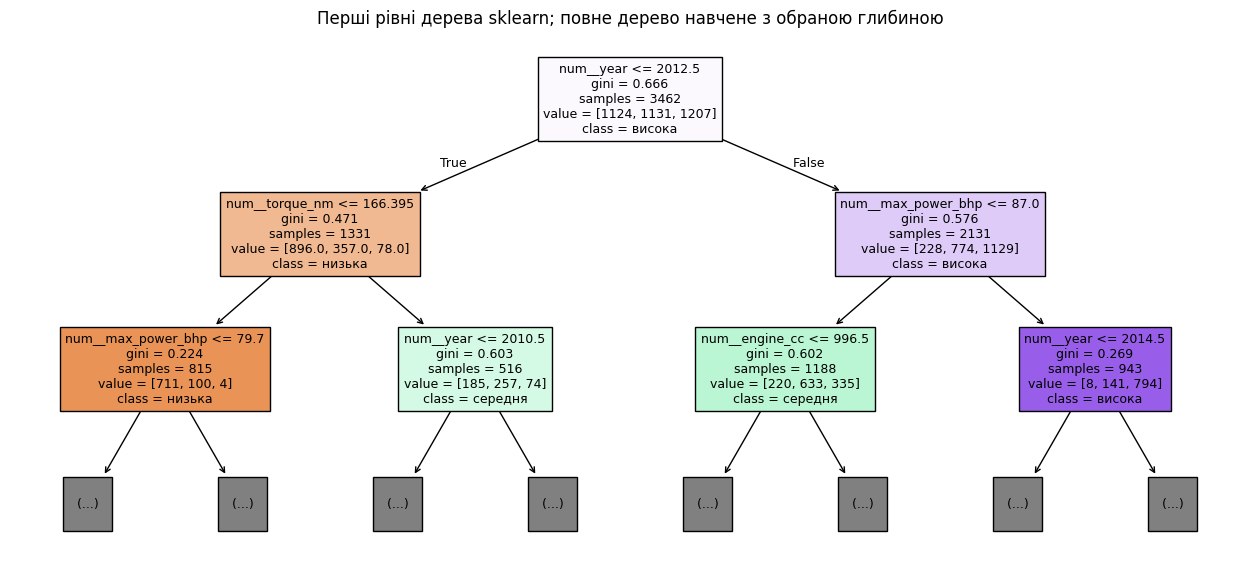

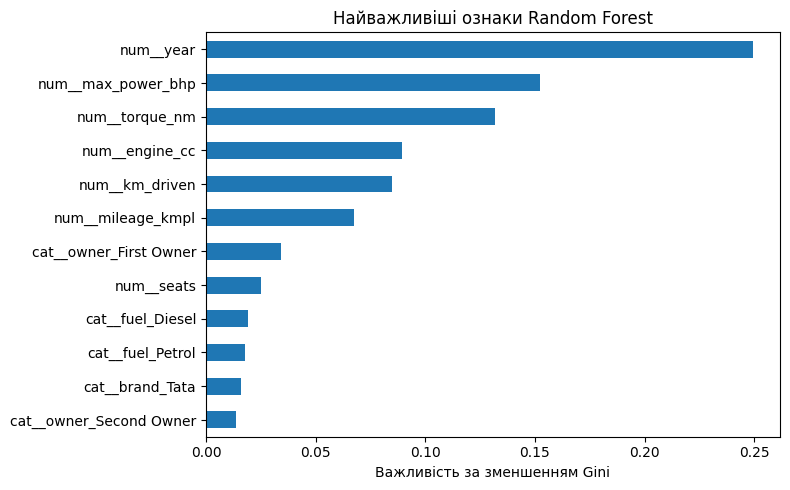

Власне дерево: точність на тесті 79.69%; помилка на навчанні 15.42%; помилка на тесті 20.31%.
Дерево sklearn: точність на тесті 79.78%; помилка на навчанні 15.42%; помилка на тесті 20.22%.
Random Forest: точність на тесті 83.10%; помилка на навчанні 9.21%; помилка на тесті 16.90%.


In [ ]:
root = models["Власне дерево"].root
if "feature" in root:
    print("Перший поділ власного дерева:", feature_names[root["feature"]],
          "<=", round(root["threshold"], 3))
    print("Gini кореня:", round(root["gini"], 4))

plt.figure(figsize=(16, 7))

# Limit the displayed depth, not the trained model depth.
plot_tree(models["Дерево sklearn"], feature_names=feature_names,
          class_names=class_names, filled=True, max_depth=2, fontsize=9)
plt.title("Перші рівні дерева sklearn; повне дерево навчене з обраною глибиною")
plt.show()

# Rank encoded features by their contribution to impurity reduction.
importance = pd.Series(models["Random Forest"].feature_importances_, index=feature_names)
importance.nlargest(12).sort_values().plot.barh(figsize=(8, 5))
plt.xlabel("Важливість за зменшенням Gini")
plt.title("Найважливіші ознаки Random Forest")
plt.tight_layout()
plt.show()

for row in results:
    print(f"{row['Модель']}: точність на тесті {row['Test accuracy']:.2%}; "
          f"помилка на навчанні {row['Train error']:.2%}; "
          f"помилка на тесті {row['Test error']:.2%}.")

Перший поділ власного дерева: `num__year ≤ 2012.500`. Важливість ознак пояснює роботу лісу, але не означає причинний вплив і може розподілятися між взаємопов’язаними ознаками.

За результатами тестування Random Forest краще класифікує автомобілі, ніж одне дерево. Власне дерево має близьку до sklearn якість. Обмеження глибини та мінімального розміру листа допомагають стримувати перенавчання.

## 9. Контрольні питання

**Що таке дерево рішень?** Це модель, яка послідовно перевіряє умови для ознак. Внутрішні вузли містять умови поділу, гілки — результати перевірки, а листи — прогнозований клас. Під час навчання обираються поділи, що зменшують нечистоту класів.

**Що таке Random Forest?** Це ансамбль дерев, які навчаються на випадкових bootstrap-вибірках. У кожному вузлі розглядається випадкова частина ознак. Для класифікації sklearn усереднює ймовірності класів від дерев і обирає клас із найбільшою середньою ймовірністю.

**Що таке чисті дані?** Це дані з узгодженими форматами й одиницями вимірювання, без необроблених помилок і небажаних дублікатів. Пропуски та аномалії мають бути виявлені й оброблені відповідно до задачі.

**Які проблеми бувають у реальних датасетах і як їх обробляти?** Пропуски можна заповнювати або видаляти за обґрунтованим правилом; дублікати — прибирати; помилкові значення — виправляти або вилучати; різні формати й одиниці — узгоджувати. У цій роботі видалила дублікати й некоректні записи, заповнила пропуски за навчальною вибіркою, закодувала категорії та розділила показники з різними одиницями. Високі ціни не видаляла лише через їх величину.
